In [4]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np

# Sử dụng gói tf_keras tương thích trên Python 3.12
import tf_keras as keras
from tf_keras.applications import MobileNetV2
from tf_keras.applications.mobilenet_v2 import preprocess_input
from tf_keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tf_keras.models import Model
from tf_keras.preprocessing.image import ImageDataGenerator

print("-> Đã nạp thành công Keras và ImageDataGenerator!")

-> Đã nạp thành công Keras và ImageDataGenerator!


In [5]:
import os
# Cấu hình tham số
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

# Đường dẫn dữ liệu
DATA_DIR = "./data_hardware"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

CLASS_NAMES = ["CPU", "GPU", "Mainboard", "PSU", "RAM", "SSD"]

# Tiền xử lý & Data Augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Nạp dữ liệu từ thư mục (Nên chuẩn bị thư mục data_hardware trước khi chạy Cell này)
try:
    train_generator = train_datagen.flow_from_directory(
        TRAIN_DIR,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True
    )

    test_generator = test_datagen.flow_from_directory(
        TEST_DIR,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )
    print("-> Đã nạp xong bộ dữ liệu Train/Test!")
except Exception as e:
    print(f"[LƯU Ý] Hãy kiểm tra lại thư mục ./data_hardware: {e}")

Found 36 images belonging to 6 classes.
Found 71 images belonging to 6 classes.
-> Đã nạp xong bộ dữ liệu Train/Test!


In [1]:
import tf_keras as keras
from tf_keras.applications import MobileNetV2
from tf_keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tf_keras.models import Model
from tf_keras.optimizers import Adam

# 1. Nạp mô hình MobileNetV2 tiền huấn luyện (bỏ phần Top classification)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Khóa các lớp của base_model lại để giữ tri thức pretrained
base_model.trainable = False

# 2. Thêm các lớp phân loại mới
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x) # Tránh overfitting
predictions = Dense(6, activation='softmax')(x) # 6 lớp linh kiện

model = Model(inputs=base_model.input, outputs=predictions)

# 3. Compile mô hình với Learning Rate thích hợp
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("-> Khởi tạo mô hình thành công!")




-> Khởi tạo mô hình thành công!


In [6]:
# Huấn luyện trong 15 - 20 Epochs
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=test_generator
)

Epoch 1/15


3/3 [==============================] - 5s 1s/step - loss: 2.4745 - accuracy: 0.0833 - val_loss: 1.3992 - val_accuracy: 0.5070
Epoch 2/15
3/3 [==============================] - 3s 1s/step - loss: 1.2060 - accuracy: 0.5556 - val_loss: 0.9665 - val_accuracy: 0.7042
Epoch 3/15
3/3 [==============================] - 4s 1s/step - loss: 0.7463 - accuracy: 0.8333 - val_loss: 0.7058 - val_accuracy: 0.8873
Epoch 4/15
3/3 [==============================] - 4s 1s/step - loss: 0.4877 - accuracy: 0.8611 - val_loss: 0.5082 - val_accuracy: 0.8873
Epoch 5/15
3/3 [==============================] - 4s 2s/step - loss: 0.2895 - accuracy: 0.9444 - val_loss: 0.4217 - val_accuracy: 0.9155
Epoch 6/15
3/3 [==============================] - 4s 1s/step - loss: 0.2116 - accuracy: 0.9722 - val_loss: 0.3705 - val_accuracy: 0.9155
Epoch 7/15
3/3 [==============================] - 4s 1s/step - loss: 0.1804 - accuracy: 0.9722 - val_loss: 0.3115 - val_accuracy: 0.9296
Epoch 8/15
3/3 [=======================

In [7]:
# Mở khóa các lớp cuối để fine-tune
base_model.trainable = True

# Chỉ cho phép train 30 lớp cuối
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Compile lại với learning rate nhỏ hơn rất nhiều
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train thêm 10 Epochs
history_fine = model.fit(
    train_generator,
    epochs=10,
    validation_data=test_generator
)

# Lưu lại model chuẩn sau khi fine-tune
import os
os.makedirs("./models", exist_ok=True)
model.save("./models/hardware_cnn_model.h5")
print("-> [THÀNH CÔNG] Đã lưu mô hình tối ưu vào ./models/hardware_cnn_model.h5")

Epoch 1/10
3/3 [==============================] - 5s 919ms/step - loss: 0.2906 - accuracy: 0.8889 - val_loss: 0.1947 - val_accuracy: 0.9155
Epoch 2/10
3/3 [==============================] - 1s 574ms/step - loss: 0.0775 - accuracy: 1.0000 - val_loss: 0.2526 - val_accuracy: 0.9014
Epoch 3/10
3/3 [==============================] - 1s 568ms/step - loss: 0.1136 - accuracy: 0.9722 - val_loss: 0.3265 - val_accuracy: 0.8873
Epoch 4/10
3/3 [==============================] - 2s 596ms/step - loss: 0.1564 - accuracy: 0.9722 - val_loss: 0.3959 - val_accuracy: 0.8873
Epoch 5/10
3/3 [==============================] - 1s 546ms/step - loss: 0.0627 - accuracy: 1.0000 - val_loss: 0.4399 - val_accuracy: 0.8732
Epoch 6/10
3/3 [==============================] - 1s 658ms/step - loss: 0.0913 - accuracy: 0.9722 - val_loss: 0.4605 - val_accuracy: 0.8732
Epoch 7/10
3/3 [==============================] - 1s 695ms/step - loss: 0.0606 - accuracy: 1.0000 - val_loss: 0.4597 - val_accuracy: 0.8732
Epoch 8/10
3/3 [====

d:\CUOI-KHOA-MINDX\.venv\Lib\site-packages\tf_keras\src\engine\training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


-> [THÀNH CÔNG] Đã lưu mô hình tối ưu vào ./models/hardware_cnn_model.h5


5/5 [==============================] - 1s 149ms/step - loss: 0.4107 - accuracy: 0.8873

---> Kết quả trên tập Test:
Test Accuracy: 88.73%
Test Loss: 0.4107


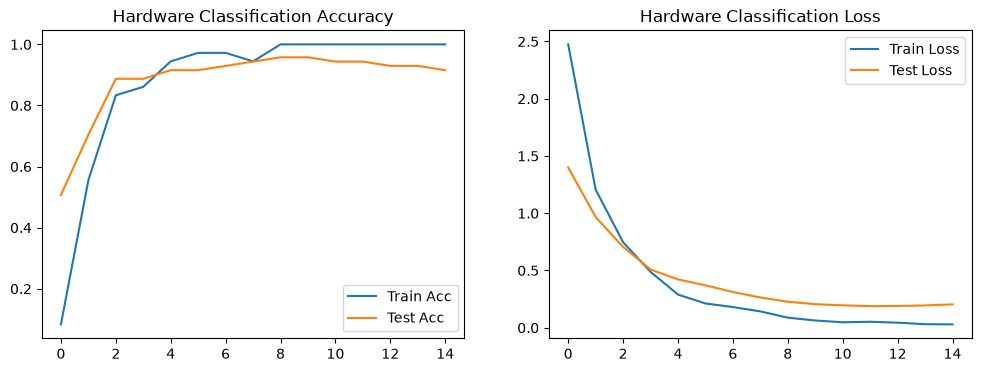

-> [THÀNH CÔNG] File 'hardware_cnn_model.h5' đã tự động tạo tại thư mục ./models/


In [8]:
# 1. Đánh giá trên tập Test
test_loss, test_acc = model.evaluate(test_generator)
print(f"\n---> Kết quả trên tập Test:")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# 2. Vẽ biểu đồ Accuracy & Loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Test Acc')
plt.title('Hardware Classification Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.title('Hardware Classification Loss')
plt.legend()

plt.show()

# 3. Tự động tạo thư mục và xuất file .h5
os.makedirs("./models", exist_ok=True)
model.save("./models/hardware_cnn_model.h5")
print("-> [THÀNH CÔNG] File 'hardware_cnn_model.h5' đã tự động tạo tại thư mục ./models/")